In [1]:
import matplotlib.pyplot as plt
import pandas as pd


In [5]:
avg_alieoptim = pd.read_csv("../results/cifar10/classic_attack/fedavg_alieoptim_1.csv")
krum_alieoptim = pd.read_csv("../results/cifar10/classic_attack/krum_alieoptim_nnm_1.csv")
median_alieoptim = pd.read_csv("../results/cifar10/classic_attack/median_alieoptim_nnm_1.csv")
multikrum_alieoptim = pd.read_csv("../results/cifar10/classic_attack/multikrum_alieoptim_1.csv")
trimmedmean_alieoptim = pd.read_csv("../results/cifar10/classic_attack/trimmedmean_alieoptim_nnm_1.csv")

In [6]:
avg_noattack = pd.read_csv("../results/cifar10/no_attack/fedavg_1.csv")
krum_noattack = pd.read_csv("../results/cifar10/no_attack/krum_nnm_1.csv")
median_noattack = pd.read_csv("../results/cifar10/no_attack/median_nnm_1.csv")
multikrum_noattack = pd.read_csv("../results/cifar10/no_attack/multikrum_1.csv")
trimmedmean_noattack = pd.read_csv("../results/cifar10/no_attack/trimmedmean_nnm_1.csv")

In [8]:
avg_stdk3 = pd.read_csv("../results/cifar10/pca_attack/fedavg_stdk3_p0_1.csv")
krum_stdk3 = pd.read_csv("../results/cifar10/pca_attack/krum_stdk3_p0_nnm_1.csv")
median_stdk3 = pd.read_csv("../results/cifar10/pca_attack/median_stdk3_p0_nnm_1.csv")
multikrum_stdk3 = pd.read_csv("../results/cifar10/pca_attack/multikrum_stdk3_p0_1.csv")
trimmedmean_stdk3 = pd.read_csv("../results/cifar10/pca_attack/trimmedmean_stdk3_p0_nnm_1.csv")

In [9]:


runs = {
    "FedAvg": {
        "no attack": avg_noattack,
        "ALIE-Optim": avg_alieoptim,
        "Stdk3": avg_stdk3
    },
    "Krum": {
        "no attack": krum_noattack,
        "ALIE-Optim": krum_alieoptim,
        "Stdk3": krum_stdk3
    },
    "Median": {
        "no attack": median_noattack,
        "ALIE-Optim": median_alieoptim,
        "Stdk3": median_stdk3
    },
    "MultiKrum": {
        "no attack": multikrum_noattack,
        "ALIE-Optim": multikrum_alieoptim,
        "Stdk3": multikrum_stdk3
    },
    "TrimmedMean": {
        "no attack": trimmedmean_noattack,
        "ALIE-Optim": trimmedmean_alieoptim,
        "Stdk3": trimmedmean_stdk3
    },
}

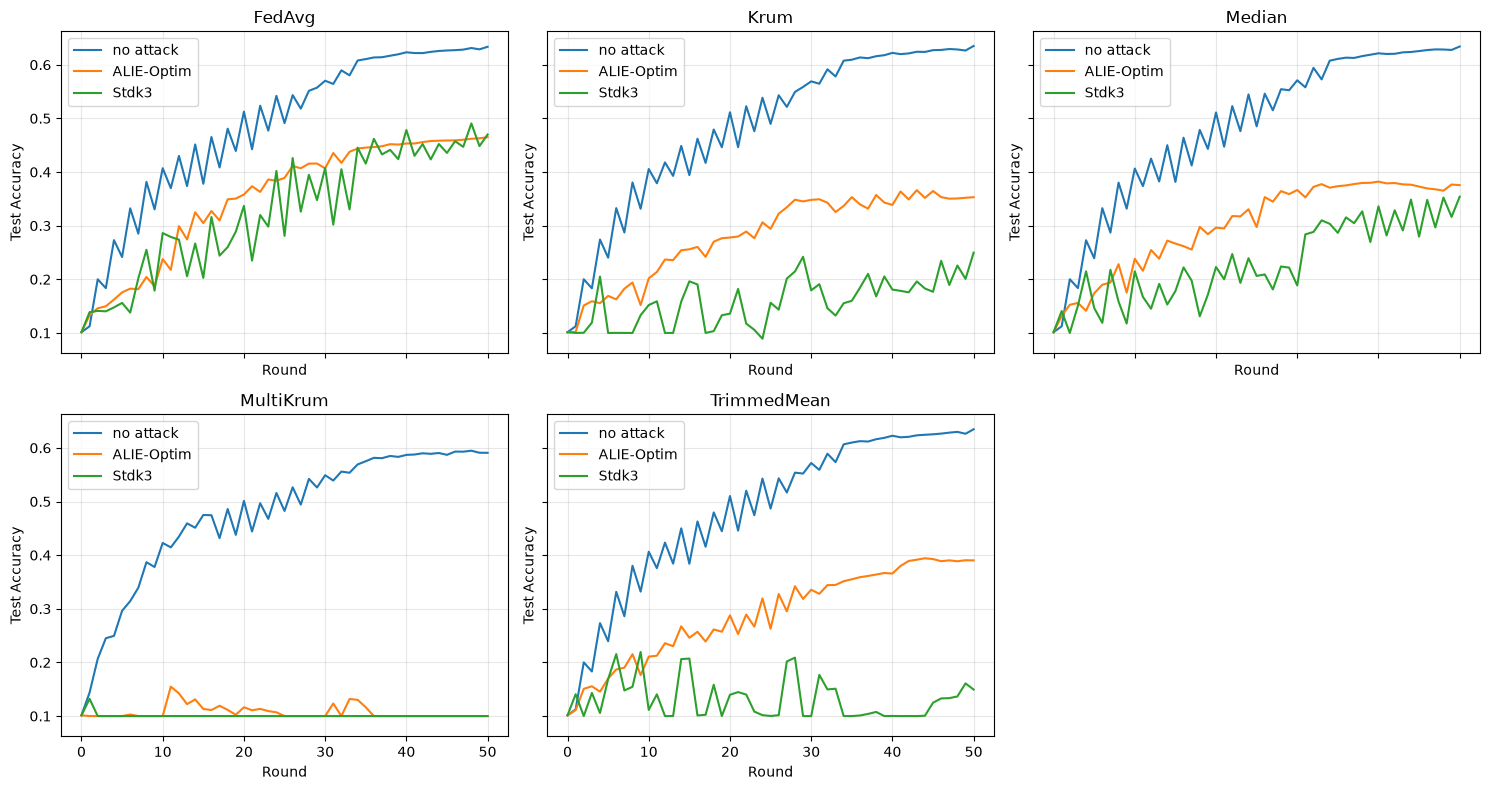

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (aggregator, variants) in zip(axes, runs.items()):
    for label, df in variants.items():
        ax.plot(df["round"], df["test_accuracy"], label=label)

    ax.set_title(aggregator)
    ax.set_xlabel("Round")
    ax.set_ylabel("Test Accuracy")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].axis("off")
plt.tight_layout()
plt.show()

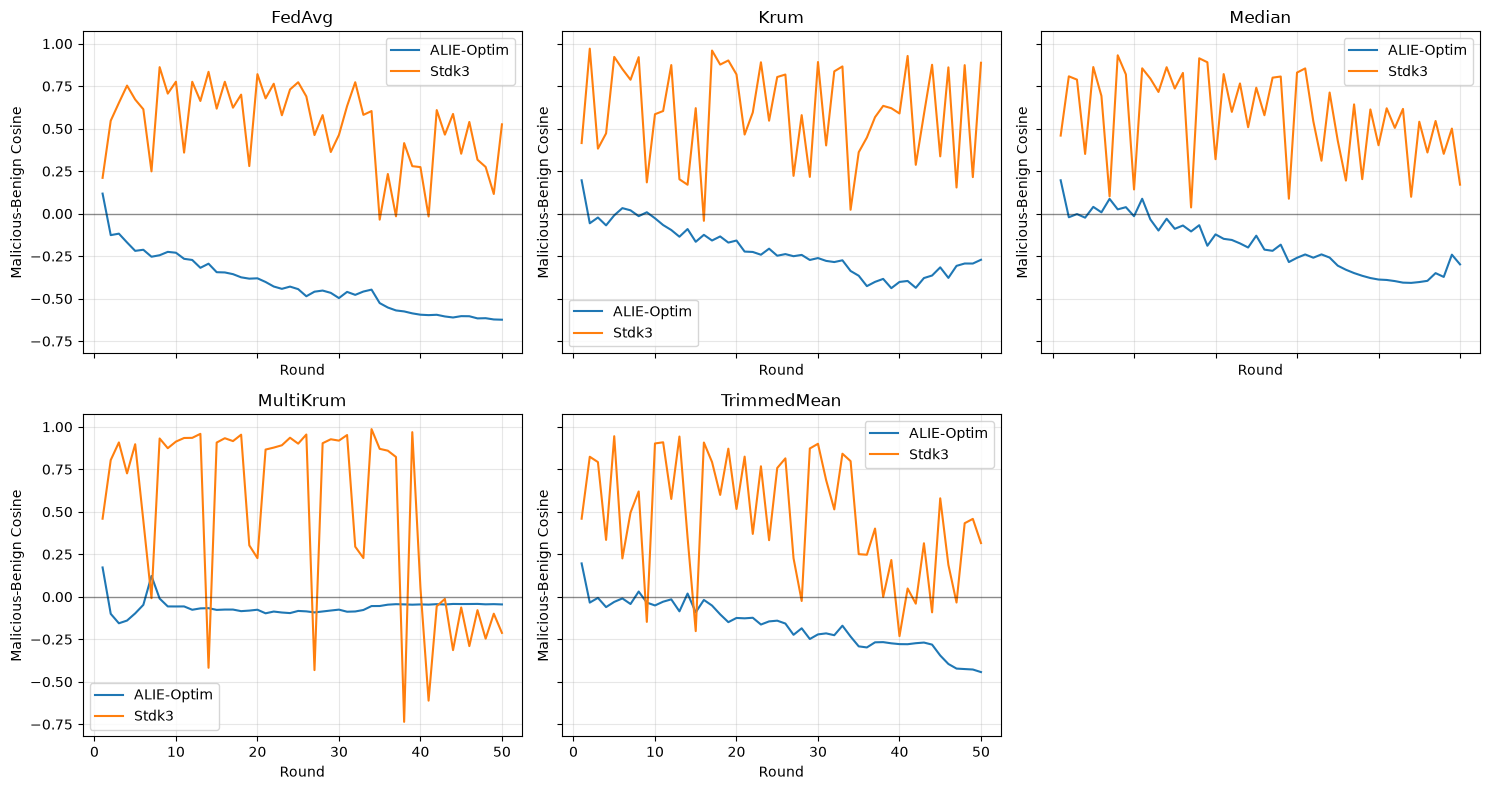

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, (aggregator, variants) in zip(axes, runs.items()):
    for label, df in variants.items():
        if label == "no attack":
            continue

        ax.plot(
            df["round"],
            df["malicious_to_benign_mean_cosine"],
            label=label,
        )

    ax.axhline(0, color="black", linewidth=1, alpha=0.4)
    ax.set_title(aggregator)
    ax.set_xlabel("Round")
    ax.set_ylabel("Malicious-Benign Cosine")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].axis("off")
plt.tight_layout()
plt.show()

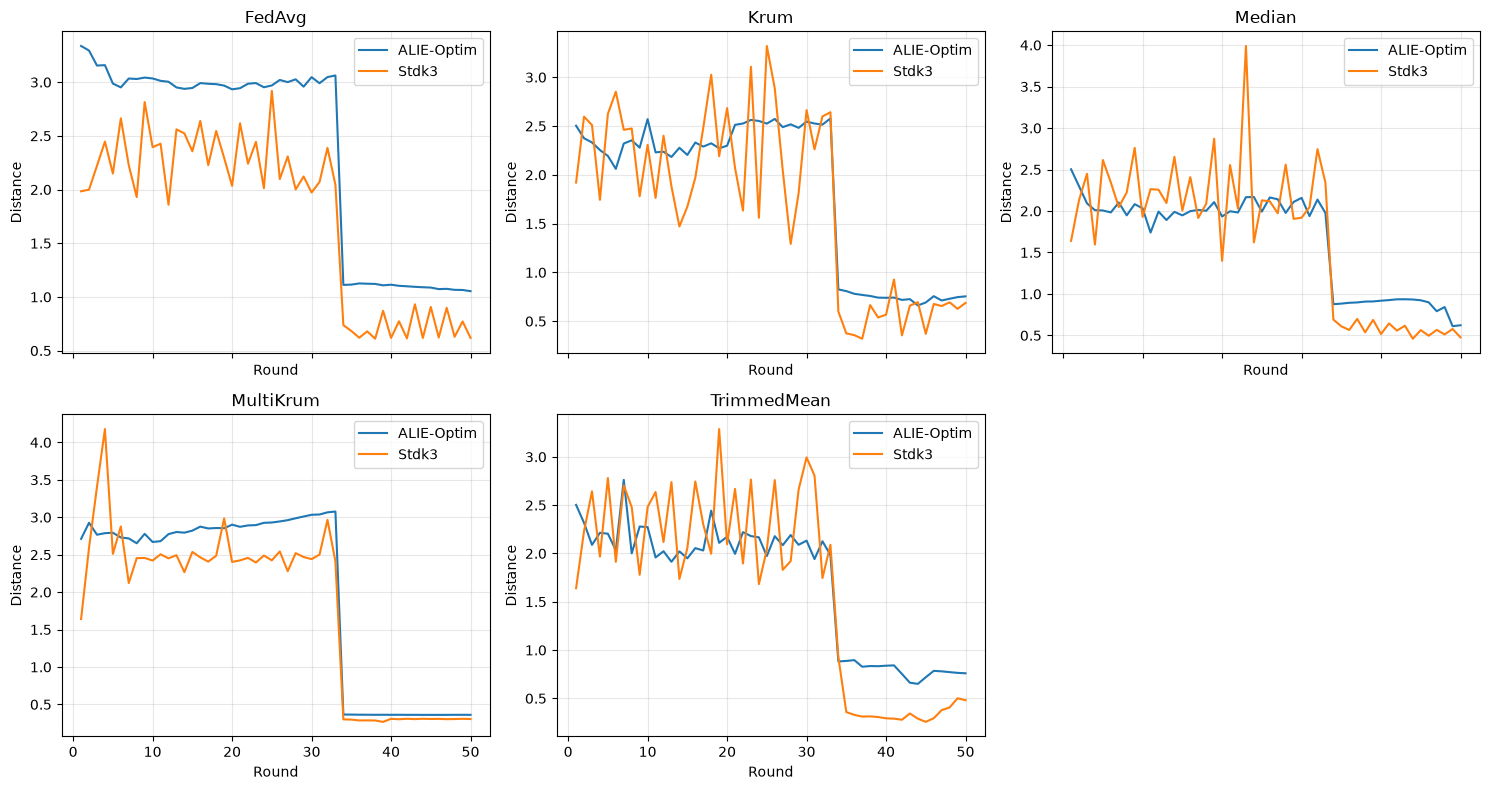

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
axes = axes.ravel()

for ax, (aggregator, variants) in zip(axes, runs.items()):
    for label, df in variants.items():
        if label == "no attack":
            continue

        ax.plot(
            df["round"],
            df["malicious_to_benign_mean_distance"],
            label=label,
        )

    ax.set_title(aggregator)
    ax.set_xlabel("Round")
    ax.set_ylabel("Distance")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].axis("off")
plt.tight_layout()
plt.show()